# Phase 4: Exploratory Data Analysis (EDA)

**Project:** Bank Customer Churn Analysis

**Goal:** understand customer churn patterns and answer the 10 business questions from Phase 1.

**Data used:** `data/processed/bank_churn_cleaned.csv` only. This notebook never changes that file. Charts are saved to `reports/eda_charts/`.

**How to read the results**
- **Churn rate** answers: "Of the customers in this group, what percentage left?" The denominator is the customers **in that group**.
- **Share of total churn** answers: "Of all customers who left, what percentage came from this group?" The denominator is **all churned customers**.
- A group can have a high rate but a small share, or a lower rate but a large share. Both views matter.
- Groups with fewer than 100 customers are flagged as small, because their percentages can be unreliable.

**Important:** these results show patterns, not causes. The data cannot tell us *why* customers left. Balance is an account amount, not revenue or profit.

Run this notebook from the `notebooks` folder, because the file paths below start from there.

## Step 1: Load the cleaned data

The fingerprint check confirms this is the same file that was validated in Phase 3. We also set the correct order for the groups, because a CSV stores them as plain text and they would otherwise sort alphabetically.

In [1]:
import hashlib
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

CLEANED_CSV = "../data/processed/bank_churn_cleaned.csv"
CHART_FOLDER = "../reports/eda_charts"
PHASE_3_FINGERPRINT = "3cf6eb4542f2c520f7f6a0831e6f0a1a31db9807abb21a12cc4266ee8bf13005"

os.makedirs(CHART_FOLDER, exist_ok=True)

with open(CLEANED_CSV, "rb") as file:
    print("Same file as Phase 3:", hashlib.sha256(file.read()).hexdigest() == PHASE_3_FINGERPRINT)

df = pd.read_csv(CLEANED_CSV)
print("Rows:", df.shape[0], "| Columns:", df.shape[1])
print("Missing values:", df.isnull().sum().sum())

Same file as Phase 3: True
Rows: 10000 | Columns: 17
Missing values: 0


In [2]:
GROUP_ORDER = {
    "country": ["France", "Germany", "Spain"],
    "gender": ["Female", "Male"],
    "age_group": ["Under 30", "30 to 39", "40 to 49", "50 to 59", "60 and above"],
    "tenure_group": ["0 to 2", "3 to 5", "6 to 8", "9 to 10"],
    "active_status": ["Inactive", "Active"],
    "products_number": [1, 2, 3, 4],
    "card_status": ["No credit card", "Has credit card"],
    "credit_score_band": ["Below 580", "580 to 669", "670 to 739", "740 to 799", "800 and above"],
    "balance_band": ["Zero", "Above 0 to 100,000", "Above 100,000 to 150,000", "Above 150,000"],
    "salary_band": ["Under 50,000", "50,000 to under 100,000", "100,000 to under 150,000", "150,000 and above"],
}

# Readable labels for the 0/1 columns. These exist only in memory, and the CSV is not changed.
# They use the Phase 1 assumption that 1 = yes, which Kaggle does not confirm.
df["active_status"] = df["active_member"].map({0: "Inactive", 1: "Active"})
df["card_status"] = df["credit_card"].map({0: "No credit card", 1: "Has credit card"})
df["churn_status"] = df["churn"].map({0: "Retained", 1: "Churned"})

## Step 2: Overall customer KPIs (Question 1)

These are the baseline numbers. Every group below is compared with the overall churn rate.

In [3]:
total_customers = len(df)
churned_customers = df["churn"].sum()
retained_customers = total_customers - churned_customers
overall_churn_rate = churned_customers / total_customers * 100
overall_retention_rate = retained_customers / total_customers * 100

print(f"Total customers:    {total_customers:,}")
print(f"Churned customers:  {churned_customers:,}")
print(f"Retained customers: {retained_customers:,}")
print(f"Churn rate:         {overall_churn_rate:.2f}%")
print(f"Retention rate:     {overall_retention_rate:.2f}%")
print()
print(f"Active member rate:           {df['active_member'].mean() * 100:.2f}%")
print(f"Average products per customer: {df['products_number'].mean():.2f}")

Total customers:    10,000
Churned customers:  2,037
Retained customers: 7,963
Churn rate:         20.37%
Retention rate:     79.63%

Active member rate:           51.51%
Average products per customer: 1.53


## Step 3: A reusable table for customer groups

We need the same calculation for ten different columns, so one small function does it. This avoids repeating code and makes sure every table uses the same denominators.

In [4]:
def churn_table(column):
    table = df.groupby(column)["churn"].agg(total_customers="count", churned="sum")
    table = table.reindex(GROUP_ORDER[column])  # put the groups in their correct order

    table["retained"] = table["total_customers"] - table["churned"]
    table["churn_rate_pct"] = table["churned"] / table["total_customers"] * 100
    table["share_of_total_churn_pct"] = table["churned"] / churned_customers * 100
    table["share_of_customers_pct"] = table["total_customers"] / total_customers * 100
    table["gap_to_overall_pts"] = table["churn_rate_pct"] - overall_churn_rate
    table["small_group"] = table["total_customers"] < 100
    return table.round(2)


tables = {column: churn_table(column) for column in GROUP_ORDER}

for column, table in tables.items():
    print(column)
    display(table)

country


,total_customers,churned,retained,churn_rate_pct,share_of_total_churn_pct,share_of_customers_pct,gap_to_overall_pts,small_group
country,,,,,,,,
France,5014,810,4204,16.15,39.76,50.14,-4.22,False
Germany,2509,814,1695,32.44,39.96,25.09,12.07,False
Spain,2477,413,2064,16.67,20.27,24.77,-3.70,False


gender


,total_customers,churned,retained,churn_rate_pct,share_of_total_churn_pct,share_of_customers_pct,gap_to_overall_pts,small_group
gender,,,,,,,,
Female,4543,1139,3404,25.07,55.92,45.43,4.70,False
Male,5457,898,4559,16.46,44.08,54.57,-3.91,False


age_group


,total_customers,churned,retained,churn_rate_pct,share_of_total_churn_pct,share_of_customers_pct,gap_to_overall_pts,small_group
age_group,,,,,,,,
Under 30,1641,124,1517,7.56,6.09,16.41,-12.81,False
30 to 39,4346,473,3873,10.88,23.22,43.46,-9.49,False
40 to 49,2618,806,1812,30.79,39.57,26.18,10.42,False
50 to 59,869,487,382,56.04,23.91,8.69,35.67,False
60 and above,526,147,379,27.95,7.22,5.26,7.58,False


... (10 outputs left out)

balance_band


,total_customers,churned,retained,churn_rate_pct,share_of_total_churn_pct,share_of_customers_pct,gap_to_overall_pts,small_group
balance_band,,,,,,,,
Zero,3617,500,3117,13.82,24.55,36.17,-6.55,False
"Above 0 to 100,000",1584,326,1258,20.58,16.00,15.84,0.21,False
"Above 100,000 to 150,000",3830,987,2843,25.77,48.45,38.30,5.40,False
"Above 150,000",969,224,745,23.12,11.00,9.69,2.75,False


salary_band


,total_customers,churned,retained,churn_rate_pct,share_of_total_churn_pct,share_of_customers_pct,gap_to_overall_pts,small_group
salary_band,,,,,,,,
"Under 50,000",2453,489,1964,19.93,24.01,24.53,-0.44,False
"50,000 to under 100,000",2537,504,2033,19.87,24.74,25.37,-0.50,False
"100,000 to under 150,000",2555,517,2038,20.23,25.38,25.55,-0.14,False
"150,000 and above",2455,527,1928,21.47,25.87,24.55,1.10,False


### Highest rate compared with largest contribution

This summary separates the two ideas for each customer characteristic. Sometimes the same group leads both, and sometimes it does not.

In [5]:
summary_rows = []

for column, table in tables.items():
    summary_rows.append({
        "characteristic": column,
        "highest_churn_rate": table["churn_rate_pct"].idxmax(),
        "rate_pct": table["churn_rate_pct"].max(),
        "customers_in_that_group": table.loc[table["churn_rate_pct"].idxmax(), "total_customers"],
        "largest_share_of_churn": table["share_of_total_churn_pct"].idxmax(),
        "share_pct": table["share_of_total_churn_pct"].max(),
        "gap_between_highest_and_lowest_rate_pts": round(table["churn_rate_pct"].max() - table["churn_rate_pct"].min(), 2),
    })

pd.DataFrame(summary_rows)

,characteristic,highest_churn_rate,rate_pct,customers_in_that_group,largest_share_of_churn,share_pct,gap_between_highest_and_lowest_rate_pts
0,country,Germany,32.44,2509,Germany,39.96,16.29
1,gender,Female,25.07,4543,Female,55.92,8.61
2,age_group,50 to 59,56.04,869,40 to 49,39.57,48.48
3,tenure_group,9 to 10,21.30,1474,3 to 5,30.68,2.43
4,active_status,Inactive,26.85,4849,Inactive,63.92,12.58
5,products_number,4,100.00,60,1,69.17,92.42
6,card_status,No credit card,20.81,2945,Has credit card,69.91,0.63
7,credit_score_band,Below 580,22.02,2362,580 to 669,33.63,3.40
8,balance_band,"Above 100,000 to 150,000",25.77,3830,"Above 100,000 to 150,000",48.45,11.95
9,salary_band,"150,000 and above",21.47,2455,"150,000 and above",25.87,1.60


## Step 4: Compare churned and retained customers

Averages can hide things, so we also look at `balance` for customers with a balance above zero. Zero balances pull the balance average down, as noted in Phase 2.

In [6]:
numeric_columns = ["age", "credit_score", "tenure", "balance", "estimated_salary", "products_number"]

averages = df.groupby("churn_status")[numeric_columns].mean().T[["Churned", "Retained"]]
averages["difference"] = averages["Churned"] - averages["Retained"]
averages.round(2)

churn_status,Churned,Retained,difference
age,44.84,37.41,7.43
credit_score,645.35,651.85,-6.50
tenure,4.93,5.03,-0.10
balance,91108.54,72745.30,18363.24
estimated_salary,101465.68,99738.39,1727.29
products_number,1.48,1.54,-0.07


In [7]:
balance_churned = df.loc[df["churn"] == 1, "balance"].sum()
balance_total = df["balance"].sum()

print(f"Total balance held by churned customers: {balance_churned:,.2f}")
print(f"Total balance held by all customers:     {balance_total:,.2f}")
print(f"Share held by churned customers:         {balance_churned / balance_total * 100:.2f}%")
print()

above_zero = df[df["balance"] > 0]
print("Average balance, customers with a balance above 0 only:")
print(above_zero.groupby("churn_status")["balance"].agg(["count", "mean"]).round(2))
print()

zero_balance_share = (df["balance"] == 0).groupby(df["churn_status"]).mean() * 100
print("Percentage of each group with a zero balance:")
print(zero_balance_share.round(2))

Total balance held by churned customers: 185,588,094.63
Total balance held by all customers:     764,858,892.88
Share held by churned customers:         24.26%

Average balance, customers with a balance above 0 only:
              count       mean
churn_status                  
Churned        1537  120746.97
Retained       4846  119535.86

Percentage of each group with a zero balance:
churn_status
Churned     24.55
Retained    39.14
Name: balance, dtype: float64


## Step 5: Country and balance together

Phase 2 found that Germany has no zero-balance customers, so country and balance can overlap. This table looks at them together.

In [8]:
country_balance = df.groupby(["country", "balance_band"])["churn"].agg(total_customers="count", churned="sum").reset_index()
country_balance["churn_rate_pct"] = (country_balance["churned"] / country_balance["total_customers"] * 100).round(2)
country_balance["share_of_total_churn_pct"] = (country_balance["churned"] / churned_customers * 100).round(2)
country_balance

,country,balance_band,total_customers,churned,churn_rate_pct,share_of_total_churn_pct
0,France,"Above 0 to 100,000",688,130,18.90,6.38
1,France,"Above 100,000 to 150,000",1476,238,16.12,11.68
2,France,"Above 150,000",432,105,24.31,5.15
3,France,Zero,2418,337,13.94,16.54
4,Germany,"Above 0 to 100,000",543,108,19.89,5.30
5,Germany,"Above 100,000 to 150,000",1652,646,39.10,31.71
6,Germany,"Above 150,000",314,60,19.11,2.95
7,Spain,"Above 0 to 100,000",353,88,24.93,4.32
8,Spain,"Above 100,000 to 150,000",702,103,14.67,5.06
9,Spain,"Above 150,000",223,59,26.46,2.90


In [9]:
germany = df[df["country"] == "Germany"]
in_band = germany["balance_band"] == "Above 100,000 to 150,000"

print(f"Germany, balance above 100,000 to 150,000: {germany[in_band]['churn'].mean() * 100:.2f}% of {in_band.sum():,} customers")
print(f"Germany, all other balances:               {germany[~in_band]['churn'].mean() * 100:.2f}% of {(~in_band).sum():,} customers")

Germany, balance above 100,000 to 150,000: 39.10% of 1,652 customers


Germany, all other balances:               19.60% of 857 customers


## Step 6: Simple combinations of two characteristics (Question 10)

We count churn for every pair of six characteristics. These are the same customers viewed in different ways, so **segments overlap and their shares must not be added together**.

**Working rule for a "priority" segment in this phase:**
- At least 100 customers.
- Churn rate at least 2 times the overall rate.
- At least 10% of all churned customers.

This rule is a simple screening choice made for this project, not a bank standard. Phase 6 can look at these segments in more depth.

In [10]:
pair_columns = ["country", "gender", "age_group", "active_status", "products_number", "balance_band"]


def describe(column, value):
    if column == "age_group":
        return f"Age {value}"
    if column == "balance_band":
        return f"Balance {value}"
    if column == "products_number":
        return f"{value} product" if value == 1 else f"{value} products"
    return str(value)


rows = []

for i in range(len(pair_columns)):
    for j in range(i + 1, len(pair_columns)):
        first = pair_columns[i]
        second = pair_columns[j]
        pair_table = df.groupby([first, second])["churn"].agg(total_customers="count", churned="sum").reset_index()

        for _, row in pair_table.iterrows():
            rows.append({
                "segment": describe(first, row[first]) + " + " + describe(second, row[second]),
                "total_customers": row["total_customers"],
                "churned": row["churned"],
                "churn_rate_pct": round(row["churned"] / row["total_customers"] * 100, 2),
                "share_of_total_churn_pct": round(row["churned"] / churned_customers * 100, 2),
            })

segments = pd.DataFrame(rows)
print("Segments checked:", len(segments))
print("Segments with fewer than 100 customers:", (segments["total_customers"] < 100).sum())

Segments checked:

 162
Segments with fewer than 100 customers: 29


In [11]:
large_enough = segments["total_customers"] >= 100
high_rate = segments["churn_rate_pct"] >= overall_churn_rate * 2
large_share = segments["share_of_total_churn_pct"] >= 10

priority_segments = segments[large_enough & high_rate & large_share].sort_values("churn_rate_pct", ascending=False)
print("Priority segments:", len(priority_segments))
print("Minimum churn rate needed:", round(overall_churn_rate * 2, 2))
priority_segments

Priority segments: 8
Minimum churn rate needed: 40.74


,segment,total_customers,churned,churn_rate_pct,share_of_total_churn_pct
85,Age 50 to 59 + Inactive,373,303,81.23,14.87
98,Age 50 to 59 + 1 product,537,344,64.06,16.89
52,Female + Age 50 to 59,421,265,62.95,13.01
119,"Age 50 to 59 + Balance Above 100,000 to 150,000",375,228,60.80,11.19
57,Male + Age 50 to 59,448,222,49.55,10.90
12,Germany + Age 40 to 49,740,334,45.14,16.40
31,Germany + 1 product,1349,578,42.85,28.38
24,Germany + Inactive,1261,518,41.08,25.43


### Highest churn rate among segments with at least 100 customers

In [12]:
segments[large_enough].sort_values("churn_rate_pct", ascending=False).head(8)

,segment,total_customers,churned,churn_rate_pct,share_of_total_churn_pct
155,"3 products + Balance Above 100,000 to 150,000",103,97,94.17,4.76
136,Inactive + 3 products,153,135,88.24,6.63
66,Female + 3 products,149,129,86.58,6.33
87,Age 60 and above + Inactive,111,95,85.59,4.66
85,Age 50 to 59 + Inactive,373,303,81.23,14.87
29,France + 3 products,104,82,78.85,4.03
70,Male + 3 products,117,91,77.78,4.47
132,Active + 3 products,113,85,75.22,4.17


### Largest number of churned customers

In [13]:
segments.sort_values("churned", ascending=False).head(8)

,segment,total_customers,churned,churn_rate_pct,share_of_total_churn_pct
134,Inactive + 1 product,2521,924,36.65,45.36
64,Female + 1 product,2296,762,33.19,37.41
61,Female + Inactive,2259,725,32.09,35.59
147,"1 product + Balance Above 100,000 to 150,000",2537,698,27.51,34.27
68,Male + 1 product,2788,647,23.21,31.76
44,"Germany + Balance Above 100,000 to 150,000",1652,646,39.10,31.71
143,"Inactive + Balance Above 100,000 to 150,000",1872,627,33.49,30.78
31,Germany + 1 product,1349,578,42.85,28.38


### Small segments (under 100 customers) with the highest churn rate

These are flagged for caution and are not treated as priorities.

In [14]:
segments[~large_enough].sort_values(["churn_rate_pct", "total_customers"], ascending=False).head(8)

,segment,total_customers,churned,churn_rate_pct,share_of_total_churn_pct
67,Female + 4 products,38,38,100.0,1.87
159,"4 products + Balance Above 100,000 to 150,000",33,33,100.0,1.62
137,Inactive + 4 products,31,31,100.0,1.52
30,France + 4 products,29,29,100.0,1.42
133,Active + 4 products,29,29,100.0,1.42
97,Age 40 to 49 + 4 products,26,26,100.0,1.28
34,Germany + 4 products,24,24,100.0,1.18
71,Male + 4 products,22,22,100.0,1.08


## Step 7: Charts

**Colour rule used throughout:** orange always means churned customers, and blue always means retained customers.

The helper functions below keep every chart consistent. Each chart is saved to `reports/eda_charts/`.

In [15]:
CHURN_COLOUR = "#eb6834"
RETAINED_COLOUR = "#2a78d6"
INK = "#0b0b0b"
MUTED_INK = "#52514e"

plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.edgecolor": "#b5b4ae",
    "axes.labelcolor": MUTED_INK,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.titlecolor": INK,
    "axes.labelsize": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.axisbelow": True,
    "axes.grid": True,
    "axes.grid.axis": "y",
    "grid.color": "#ecebe7",
    "xtick.color": MUTED_INK,
    "ytick.color": MUTED_INK,
    "font.size": 11,
    "legend.frameon": False,
})


def save_chart(file_name):
    plt.tight_layout()
    plt.savefig(f"{CHART_FOLDER}/{file_name}.png", dpi=150, bbox_inches="tight")
    plt.show()


def wrap_label(label):
    # Put long group names on two lines so they do not overlap
    label = str(label)
    return label.replace(" to ", " to\n") if len(label) > 12 else label


def bar_panel(ax, table, value_column, title, x_label, y_label, y_max, show_overall=True, label_size=9):
    labels = [wrap_label(label) for label in table.index]
    bars = ax.bar(labels, table[value_column], color=CHURN_COLOUR, width=0.65)

    for bar, value, customers, is_small in zip(bars, table[value_column], table["total_customers"], table["small_group"]):
        if is_small:
            bar.set_hatch("///")  # a pattern marks small groups, so colour is not the only signal
            bar.set_edgecolor("white")
        note = f"{customers:,} customers" + (" (small)" if is_small else "")
        ax.text(bar.get_x() + bar.get_width() / 2, value + y_max * 0.015, f"{value:.1f}%\n{note}",
                ha="center", va="bottom", fontsize=label_size, color=INK, zorder=5,
                bbox={"facecolor": "white", "edgecolor": "none", "pad": 1})  # keeps labels readable over the line

    if show_overall:
        ax.axhline(overall_churn_rate, color=INK, linestyle="--", linewidth=1,
                   label=f"Overall churn rate ({overall_churn_rate:.1f}%)")
        ax.legend(loc="upper left")

    ax.set_title(title, loc="left")
    ax.set_xlabel(x_label)
    ax.set_ylabel(y_label)
    ax.set_ylim(0, y_max)

### Chart 1: Churned and retained customers

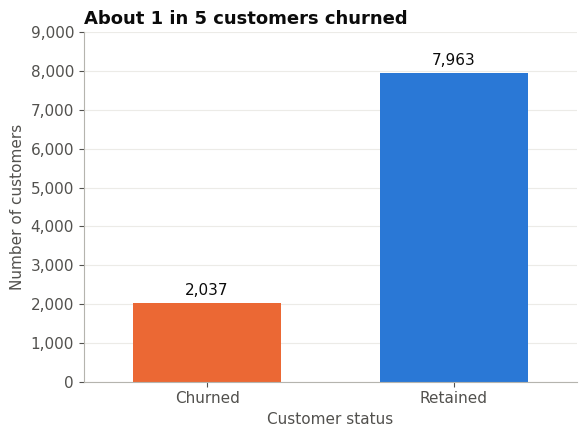

In [16]:
fig, ax = plt.subplots(figsize=(6, 4.5))
sns.countplot(data=df, x="churn_status", order=["Churned", "Retained"], hue="churn_status",
              palette={"Churned": CHURN_COLOUR, "Retained": RETAINED_COLOUR}, saturation=1, width=0.6, ax=ax)

for bars in ax.containers:
    ax.bar_label(bars, fmt="{:,.0f}", padding=3, color=INK)

ax.set_title("About 1 in 5 customers churned", loc="left")
ax.set_xlabel("Customer status")
ax.set_ylabel("Number of customers")
ax.set_ylim(0, 9000)
ax.yaxis.set_major_formatter(lambda value, position: f"{value:,.0f}")
save_chart("01_churned_vs_retained")

**What it shows:** of 10,000 customers, 2,037 churned (20.37%) and 7,963 were retained (79.63%). This is the baseline for every comparison below.

### Chart 2: Customers by country

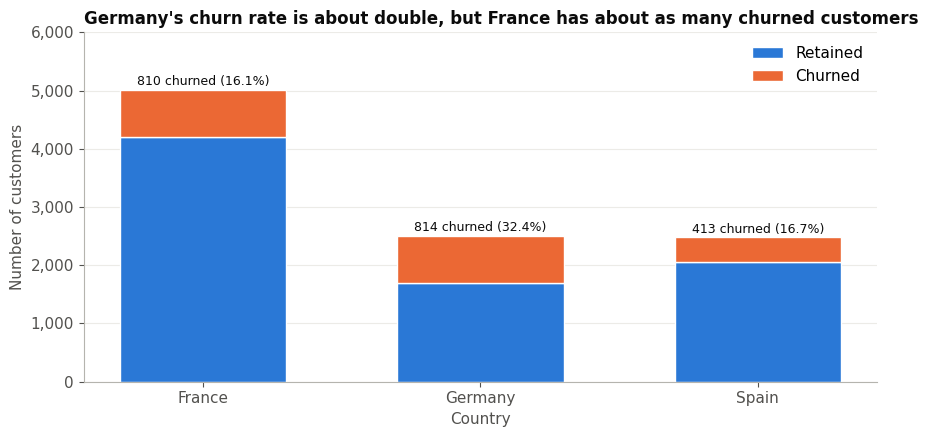

In [17]:
table = tables["country"]

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar(table.index, table["retained"], color=RETAINED_COLOUR, width=0.6, label="Retained", edgecolor="white")
ax.bar(table.index, table["churned"], bottom=table["retained"], color=CHURN_COLOUR, width=0.6, label="Churned", edgecolor="white")

for position, country in enumerate(table.index):
    ax.text(position, table.loc[country, "total_customers"] + 80,
            f"{table.loc[country, 'churned']:,} churned ({table.loc[country, 'churn_rate_pct']:.1f}%)",
            ha="center", fontsize=9, color=INK)

ax.set_title("Germany's churn rate is about double, but France has about as many churned customers", loc="left", fontsize=12)
ax.set_xlabel("Country")
ax.set_ylabel("Number of customers")
ax.set_ylim(0, 6000)
ax.yaxis.set_major_formatter(lambda value, position: f"{value:,.0f}")
ax.legend(loc="upper right")
save_chart("02_customers_by_country")

**What it shows:** Germany has the highest churn rate (32.44%), about double France (16.15%) and Spain (16.67%). Germany and France still contribute almost the same number of churned customers (814 and 810), because France has twice as many customers.

### Chart 3: Gender and active membership

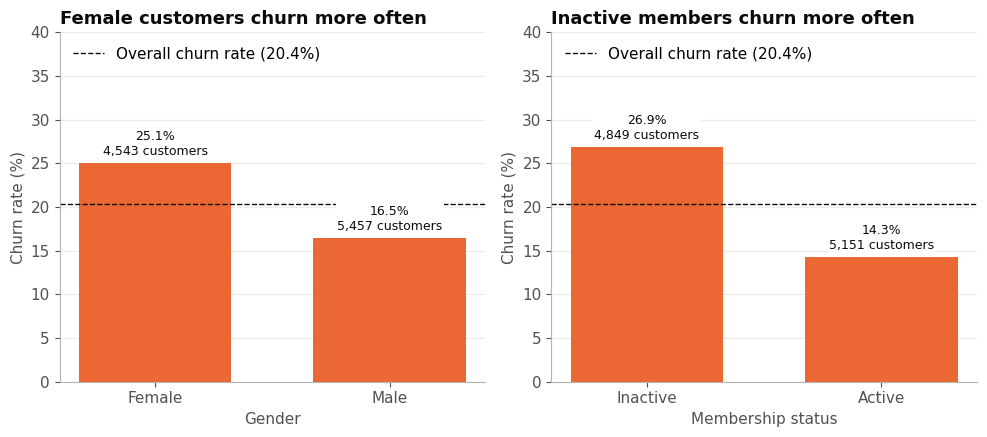

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5), sharey=True)

bar_panel(axes[0], tables["gender"], "churn_rate_pct", "Female customers churn more often", "Gender", "Churn rate (%)", 40)
bar_panel(axes[1], tables["active_status"], "churn_rate_pct", "Inactive members churn more often", "Membership status", "Churn rate (%)", 40)
axes[1].tick_params(labelleft=True)
save_chart("03_churn_rate_gender_active")

**What it shows:** the churn rate is 25.07% for female customers and 16.46% for male customers. It is 26.85% for inactive members and 14.27% for active members. Inactive members are 48.49% of customers but 63.92% of churned customers.

### Chart 4: Age group

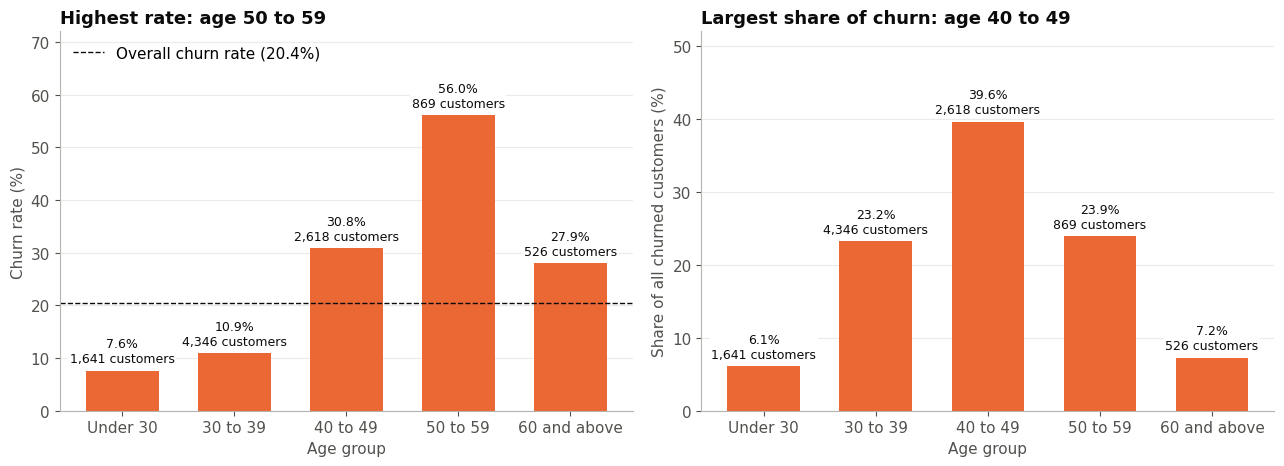

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

bar_panel(axes[0], tables["age_group"], "churn_rate_pct", "Highest rate: age 50 to 59", "Age group", "Churn rate (%)", 72)
bar_panel(axes[1], tables["age_group"], "share_of_total_churn_pct", "Largest share of churn: age 40 to 49", "Age group",
          "Share of all churned customers (%)", 52, show_overall=False)
save_chart("04_age_group_rate_and_share")

**What it shows:** ages 50 to 59 have the highest churn rate (56.04%), but ages 40 to 49 contribute the most churned customers (39.57% of the total), because that group is about three times larger.

### Chart 5: Number of products

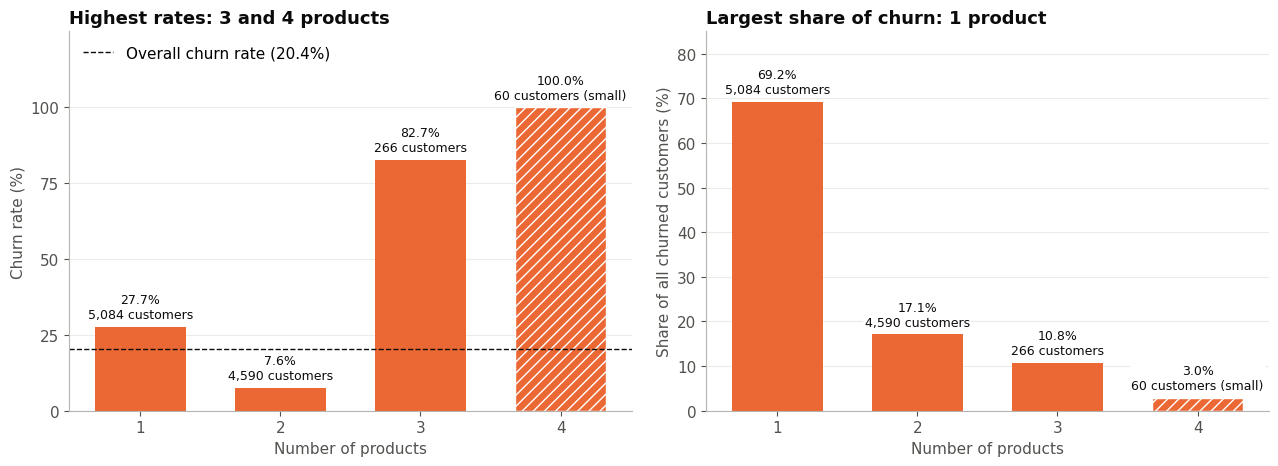

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

bar_panel(axes[0], tables["products_number"], "churn_rate_pct", "Highest rates: 3 and 4 products", "Number of products", "Churn rate (%)", 125)
bar_panel(axes[1], tables["products_number"], "share_of_total_churn_pct", "Largest share of churn: 1 product", "Number of products",
          "Share of all churned customers (%)", 85, show_overall=False)
axes[0].set_yticks([0, 25, 50, 75, 100])
save_chart("05_products_rate_and_share")

**What it shows:** all 60 customers with 4 products churned (flagged as a small group), and 82.71% of the 266 with 3 products churned. The largest contribution comes from customers with 1 product (69.17% of churn). Customers with 2 products have the lowest rate (7.58%).

### Chart 6: Balance band

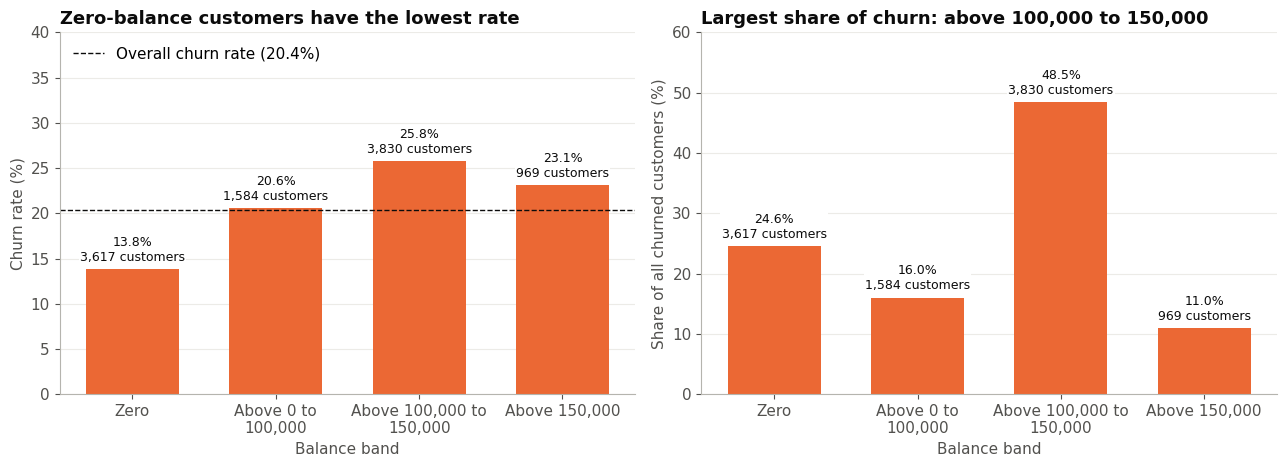

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

bar_panel(axes[0], tables["balance_band"], "churn_rate_pct", "Zero-balance customers have the lowest rate", "Balance band", "Churn rate (%)", 40)
bar_panel(axes[1], tables["balance_band"], "share_of_total_churn_pct", "Largest share of churn: above 100,000 to 150,000", "Balance band",
          "Share of all churned customers (%)", 60, show_overall=False)
save_chart("06_balance_rate_and_share")

**What it shows:** the "Above 100,000 to 150,000" band has both the highest rate (25.77%) and the largest share of churn (48.45%). Zero-balance customers have the lowest rate (13.82%). The next chart shows that this pattern is not the same in every country.

### Chart 7: Balance band within each country

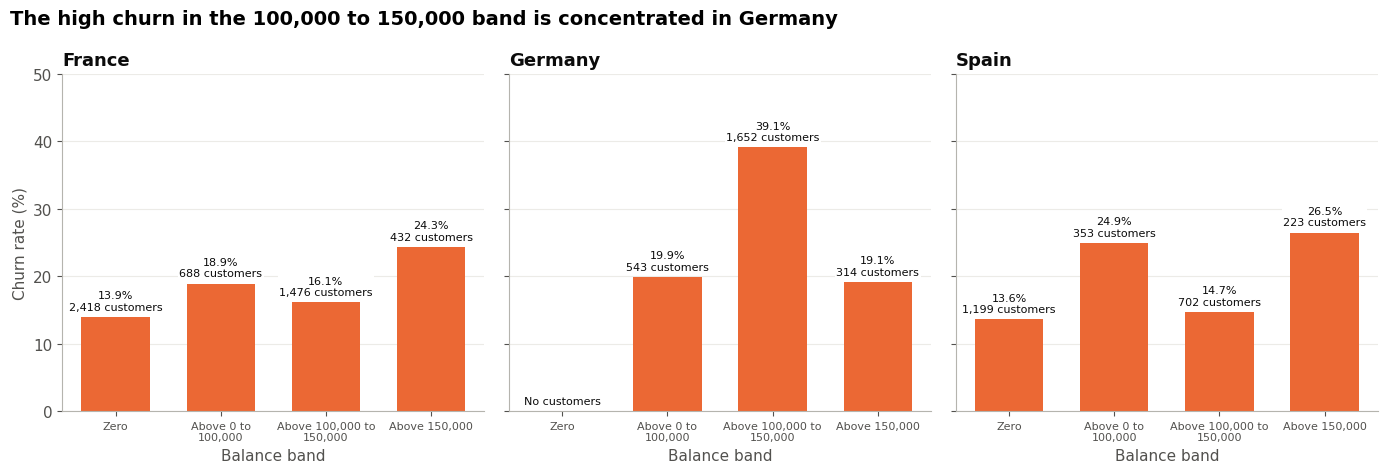

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.8), sharey=True)

for ax, country in zip(axes, GROUP_ORDER["country"]):
    rows_for_country = country_balance[country_balance["country"] == country].set_index("balance_band")
    panel = rows_for_country.reindex(GROUP_ORDER["balance_band"]).fillna(0)
    panel["total_customers"] = panel["total_customers"].astype(int)  # fillna made these decimals
    panel["small_group"] = False
    bar_panel(ax, panel, "churn_rate_pct", country, "Balance band", "Churn rate (%)", 50, show_overall=False, label_size=8)
    ax.tick_params(axis="x", labelsize=8)

    if country == "Germany":
        # Germany has no zero-balance customers, so replace the "0.0%" label with a clear note
        for text in ax.texts:
            if text.get_text().startswith("0.0%"):
                text.set_text("No customers")

axes[1].set_ylabel("")
axes[2].set_ylabel("")
fig.suptitle("The high churn in the 100,000 to 150,000 band is concentrated in Germany", x=0.01, ha="left", fontsize=14, fontweight="bold")
save_chart("07_balance_rate_by_country")

**What it shows:** German customers with a balance above 100,000 to 150,000 have a 39.10% churn rate, and they alone are 31.71% of all churned customers. The same band is 16.12% in France and 14.67% in Spain. All other German customers have a 19.60% rate. So the Germany and balance findings overlap, and neither should be read alone.

### Chart 8: Characteristics with little difference

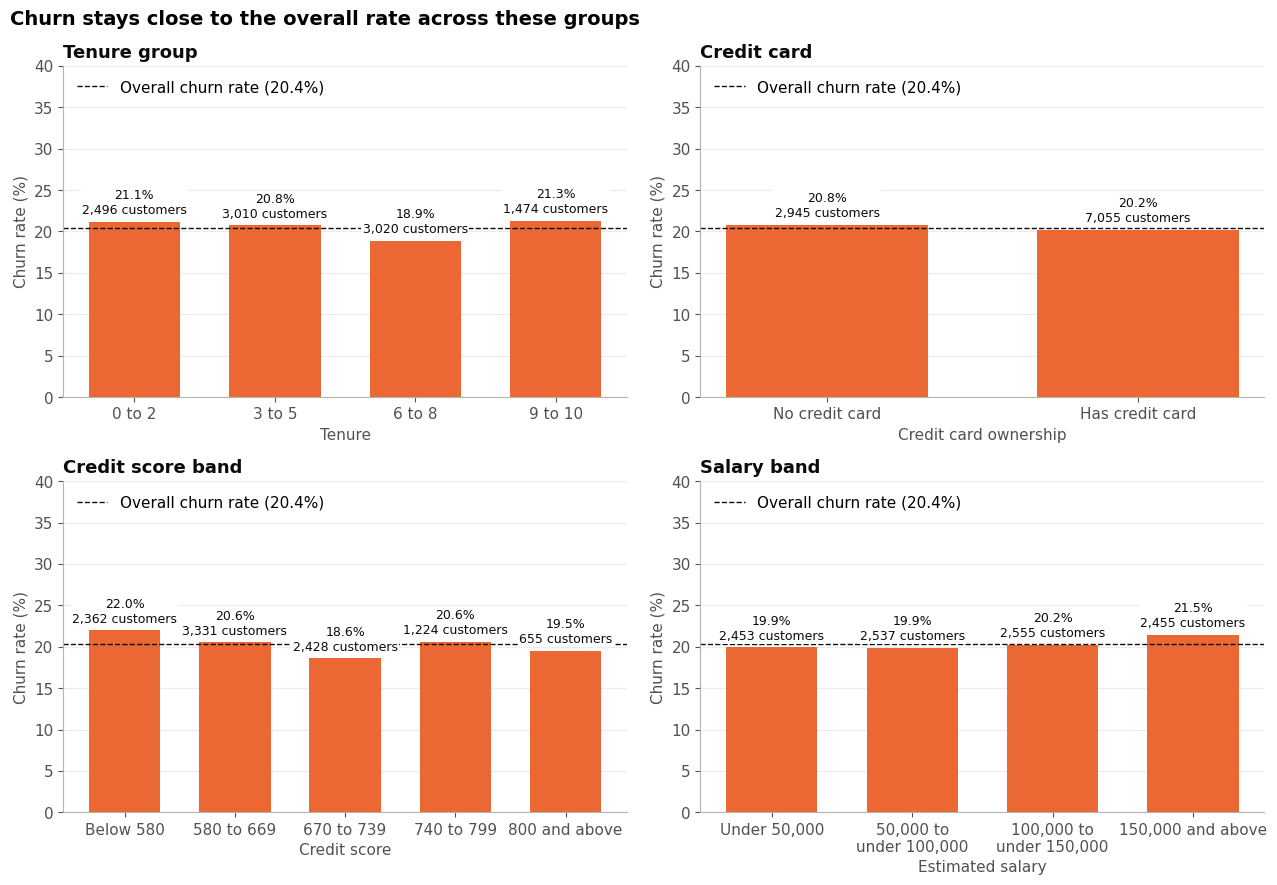

In [23]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9), sharey=True)

bar_panel(axes[0, 0], tables["tenure_group"], "churn_rate_pct", "Tenure group", "Tenure", "Churn rate (%)", 40)
bar_panel(axes[0, 1], tables["card_status"], "churn_rate_pct", "Credit card", "Credit card ownership", "Churn rate (%)", 40)
bar_panel(axes[1, 0], tables["credit_score_band"], "churn_rate_pct", "Credit score band", "Credit score", "Churn rate (%)", 40)
bar_panel(axes[1, 1], tables["salary_band"], "churn_rate_pct", "Salary band", "Estimated salary", "Churn rate (%)", 40)

for ax in axes.flat:
    ax.tick_params(labelleft=True)

fig.suptitle("Churn stays close to the overall rate across these groups", x=0.01, ha="left", fontsize=14, fontweight="bold")
save_chart("08_little_difference_groups")

**What it shows:** all of these groups sit within about 3.4 percentage points of each other at most (tenure 2.43, credit card 0.63, credit score 3.40, salary 1.60). These characteristics do not separate churned from retained customers much when viewed one at a time.

### Chart 9: Age distribution

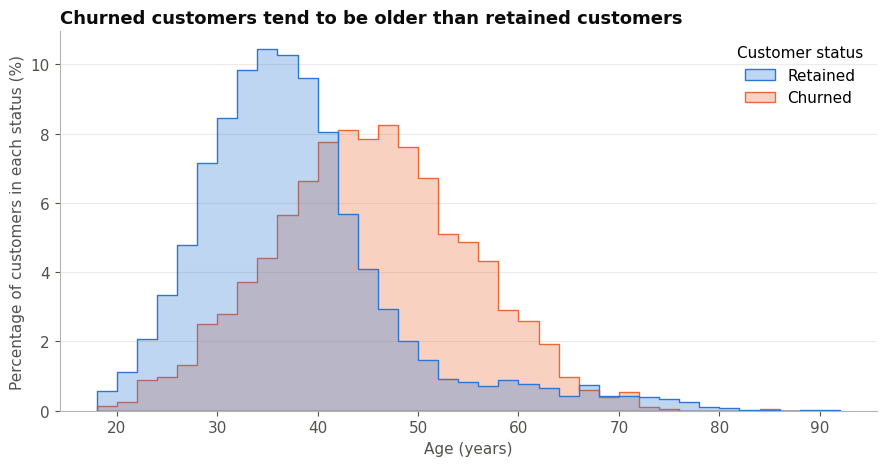

In [24]:
fig, ax = plt.subplots(figsize=(9, 4.8))

# stat="percent" with common_norm=False shows each group as a percentage of itself.
# Without this, the larger retained group would look bigger everywhere.
sns.histplot(data=df, x="age", hue="churn_status", hue_order=["Retained", "Churned"],
             palette={"Churned": CHURN_COLOUR, "Retained": RETAINED_COLOUR},
             stat="percent", common_norm=False, binwidth=2, element="step", fill=True, alpha=0.3, ax=ax)

ax.set_title("Churned customers tend to be older than retained customers", loc="left")
ax.set_xlabel("Age (years)")
ax.set_ylabel("Percentage of customers in each status (%)")
ax.get_legend().set_title("Customer status")
ax.get_legend().set_frame_on(False)
save_chart("09_age_distribution")

**What it shows:** the churned group is centred at older ages (average 44.84) than the retained group (average 37.41).

### Chart 10: Balance for customers with a balance above zero

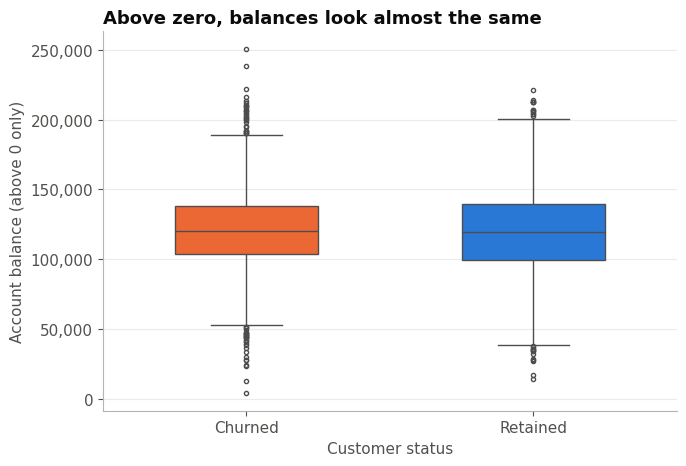

In [25]:
fig, ax = plt.subplots(figsize=(7, 4.8))

sns.boxplot(data=above_zero, x="churn_status", y="balance", order=["Churned", "Retained"], hue="churn_status",
            palette={"Churned": CHURN_COLOUR, "Retained": RETAINED_COLOUR}, saturation=1, width=0.5, ax=ax,
            flierprops={"markersize": 3})

ax.set_title("Above zero, balances look almost the same", loc="left")
ax.set_xlabel("Customer status")
ax.set_ylabel("Account balance (above 0 only)")
ax.yaxis.set_major_formatter(lambda value, position: f"{value:,.0f}")
save_chart("10_balance_boxplot_above_zero")

**What it shows:** churned customers have a higher overall average balance (91,108.54 compared with 72,745.30), but above zero the averages are almost equal (120,746.97 and 119,535.86). The overall gap mainly reflects that fewer churned customers have a zero balance (24.55% compared with 39.14%).

### Chart 11: Priority segments

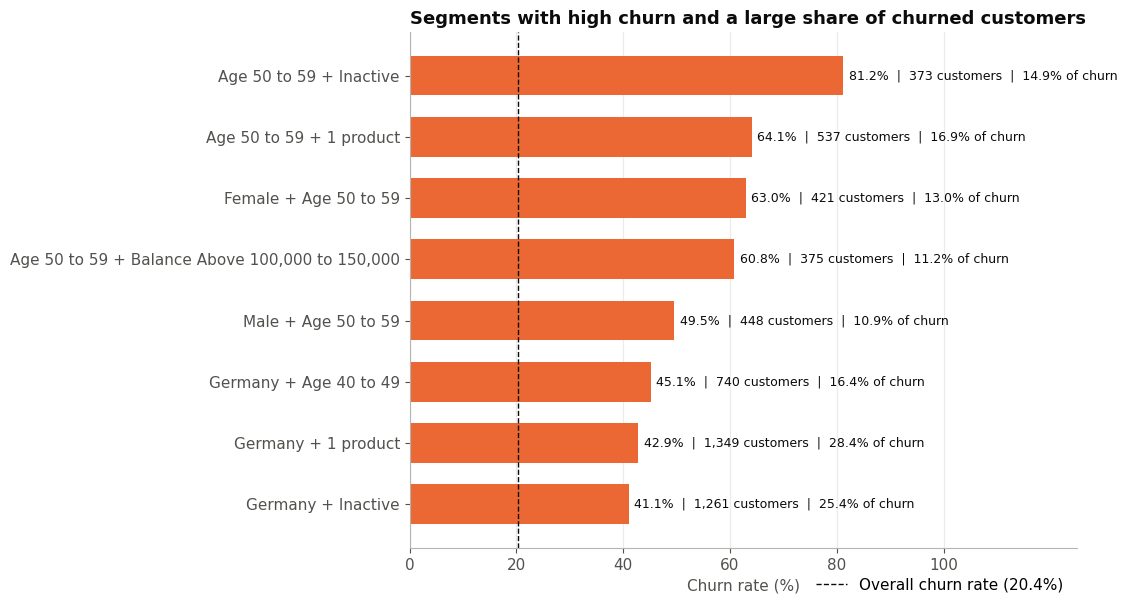

In [26]:
chart_data = priority_segments.sort_values("churn_rate_pct")

fig, ax = plt.subplots(figsize=(11, 0.55 * len(chart_data) + 1.8))
bars = ax.barh(chart_data["segment"], chart_data["churn_rate_pct"], color=CHURN_COLOUR, height=0.65)

for bar, row in zip(bars, chart_data.itertuples()):
    ax.text(bar.get_width() + 1, bar.get_y() + bar.get_height() / 2,
            f"{row.churn_rate_pct:.1f}%  |  {row.total_customers:,} customers  |  {row.share_of_total_churn_pct:.1f}% of churn",
            va="center", fontsize=9, color=INK)

ax.axvline(overall_churn_rate, color=INK, linestyle="--", linewidth=1, label=f"Overall churn rate ({overall_churn_rate:.1f}%)")
ax.set_title("Segments with high churn and a large share of churned customers", loc="left")
ax.set_xlabel("Churn rate (%)")
ax.set_ylabel("")
ax.set_xlim(0, 125)
ax.set_xticks([0, 20, 40, 60, 80, 100])
ax.grid(axis="x", color="#ecebe7")
ax.grid(axis="y", visible=False)
ax.legend(loc="upper right", bbox_to_anchor=(1, -0.03))
save_chart("11_priority_segments")

**What it shows:** 8 segments meet the working rule, and they fall into two clusters: customers aged 50 to 59 and German customers. The highest rate is among inactive customers aged 50 to 59 (81.23% of 373 customers). These segments overlap, so their shares must not be added together. A separate view matters too: inactive customers with 1 product have a lower rate (36.65%) but the largest number of churned customers (924, or 45.36% of the total).

## Step 8: Validation

Each check prints PASS or FAIL. Expected counts come from Phase 3.

In [27]:
results = []


def check(description, passed):
    results.append(bool(passed))
    print("PASS" if passed else "FAIL", "-", description)


phase_3_counts = {
    "age_group": {"Under 30": 1641, "30 to 39": 4346, "40 to 49": 2618, "50 to 59": 869, "60 and above": 526},
    "tenure_group": {"0 to 2": 2496, "3 to 5": 3010, "6 to 8": 3020, "9 to 10": 1474},
    "credit_score_band": {"Below 580": 2362, "580 to 669": 3331, "670 to 739": 2428, "740 to 799": 1224, "800 and above": 655},
    "salary_band": {"Under 50,000": 2453, "50,000 to under 100,000": 2537, "100,000 to under 150,000": 2555, "150,000 and above": 2455},
    "balance_band": {"Zero": 3617, "Above 0 to 100,000": 1584, "Above 100,000 to 150,000": 3830, "Above 150,000": 969},
}

check("10,000 customers and 17 CSV columns", len(df) == 10000 and pd.read_csv(CLEANED_CSV).shape[1] == 17)
check("Churned customers match Phase 2 (2,037)", churned_customers == 2037)
check("Retained customers match Phase 2 (7,963)", retained_customers == 7963)
check("Churned + retained = total", churned_customers + retained_customers == total_customers)
check("Churn rate + retention rate = 100%", np.isclose(overall_churn_rate + overall_retention_rate, 100))
check("No missing values", df.isnull().sum().sum() == 0)

for column, table in tables.items():
    totals_ok = (table["total_customers"].sum() == 10000 and table["churned"].sum() == 2037 and table["retained"].sum() == 7963)
    check(f"{column}: segment totals add up to 10,000 / 2,037 / 7,963", totals_ok)
    check(f"{column}: shares add up to 100%", abs(table["share_of_total_churn_pct"].sum() - 100) < 0.1)

    # Recalculate the churn rate another way, using crosstab, to confirm the denominator
    second_method = pd.crosstab(df[column], df["churn"], normalize="index")[1] * 100
    check(f"{column}: churn rate agrees with a second calculation",
          np.allclose(table["churn_rate_pct"], second_method.reindex(table.index), atol=0.01))

for column, expected in phase_3_counts.items():
    check(f"{column}: customer counts match Phase 3", tables[column]["total_customers"].to_dict() == expected)

with open(CLEANED_CSV, "rb") as file:
    check("Cleaned CSV is unchanged", hashlib.sha256(file.read()).hexdigest() == PHASE_3_FINGERPRINT)

print()
print("Checks passed:", sum(results), "of", len(results))

PASS - 10,000 customers and 17 CSV columns
PASS - Churned customers match Phase 2 (2,037)
PASS - Retained customers match Phase 2 (7,963)
PASS - Churned + retained = total
PASS - Churn rate + retention rate = 100%
PASS - No missing values
PASS - country: segment totals add up to 10,000 / 2,037 / 7,963
PASS - country: shares add up to 100%
PASS - country: churn rate agrees with a second calculation
PASS - gender: segment totals add up to 10,000 / 2,037 / 7,963
PASS - gender: shares add up to 100%
PASS - gender: churn rate agrees with a second calculation
PASS - age_group: segment totals add up to 10,000 / 2,037 / 7,963
PASS - age_group: shares add up to 100%
PASS - age_group: churn rate agrees with a second calculation
PASS - tenure_group: segment totals add up to 10,000 / 2,037 / 7,963
PASS - tenure_group: shares add up to 100%
PASS - tenure_group: churn rate agrees with a second calculation
PASS - active_status: segment totals add up to 10,000 / 2,037 / 7,963
PASS - active_status: sha